#**HackNASA — Tierra, Luna y Marte:**

**Edición automática para el equipo.** Abrir en Google Colab y ejecutar desde la primera celda. Todas las fuentes son públicas:
- **Tierra:** Microsoft Planetary Computer / Copernicus GLO-30, usando STAC y acceso firmado a teselas.
- **Luna:** NASA LOLA LDEM_80S_80MPP_ADJ.TIF (GeoTIFF optimizado para nube, se intenta leer por bloques).
- **Marte:** DLR/ESA HRSC HMC_11E10_da5.tif (se intenta leer por bloques; si el servidor no lo permite, descarga automática con límite de tamaño configurable).

Los archivos **no necesitan estar en Google Drive**. Solo los recortes pequeños se guardan en `/content/HackNASA_salidas/`. La conectividad y la posibilidad de descarga parcial dependen de los servidores externos: si el archivo DLR requiere descarga completa, puede ser considerablemente grande. No hay DEMs sintéticos ocultos ni sustitución silenciosa de datos.

**Método:** 80 m/px nominal; DEMs terrestres Copernicus, lunares LOLA y marcianos HRSC; pendientes, curvatura y rugosidad; parches; 8 características; comparación geométrica sin pendiente; ranking combinado; validación exploratoria. Es comparación morfológica, no validación geológica.


## PASO 1 — Instalar dependencias

Se instala una sola vez por sesión de Colab.

In [ ]:
%pip install -q pystac-client planetary-computer rasterio scipy pandas matplotlib

## PASO 2 — Importar librerías

NumPy, Rasterio, SciPy, STAC, Pandas y Matplotlib.

In [ ]:
from pathlib import Path
import os, json, zipfile, warnings
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import reproject, transform_bounds, Resampling
from rasterio.transform import from_origin
from rasterio.windows import Window
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
from IPython.display import display
from pystac_client import Client
import planetary_computer

## PASO 3 — Definir regiones y parámetros de comparación

Resolución objetivo de 80 m; parches de 38 × 38 píxeles (~3.04 km), salto de 19 píxeles.

In [ ]:
SALIDAS = Path('/content/HackNASA_salidas')
SALIDAS.mkdir(exist_ok=True)
API_STAC = 'https://planetarycomputer.microsoft.com/api/stac/v1'
COLECCION = 'cop-dem-glo-30'
RES_M = 80.0            # metros/pixel para los 3 cuerpos
TAM_PIX = 38             # parches de 3.04 km de lado
SALTO_PIX = 19           # 50% de traslape
COBERTURA_MIN = 0.85
PESO_FISICO = 0.5        # ponderacion inicial, por validar
CANDIDATOS_GEOM = None  # None = todos; 20 = solo Top 20 por distancia fisica

CARACTERISTICAS = [
    'pendiente_media','pendiente_std','pendiente_p90',
    'curvatura_abs_media','curvatura_abs_p90',
    'rugosidad_mediana','rugosidad_p90','rugosidad_std'
]

# Bounding boxes: oeste, sur, este, norte (grados terrestres)
ZONAS_TERRESTRES = {
    'Monterrey': [-100.50, 25.55, -100.40, 25.65],
    'Atacama': [-68.45, -23.50, -68.33, -23.40],
    'Teide': [-16.72, 28.20, -16.58, 28.32],
    'MeteorCrater': [-111.08, 34.97, -110.96, 35.09]
}
print('Configuracion lista:', RES_M, 'm/px,', len(ZONAS_TERRESTRES), 'regiones terrestres')

Configuracion lista: 80.0 m/px, 4 regiones terrestres


## PASO 4 — Funciones para consultar y recortar Copernicus

Recorta zonas terrestres y reproyecta localmente a UTM en metros.

In [ ]:
def utm_epsg(bbox):
    o, s, e, n = bbox
    lon, lat = (o + e) / 2, (s + n) / 2
    zona = min(60, max(1, int((lon + 180) // 6) + 1))
    return f'EPSG:{(32600 if lat >= 0 else 32700) + zona}'


def bajar_copernicus(catalogo, nombre, bbox):
    crs = utm_epsg(bbox)
    xmin, ymin, xmax, ymax = transform_bounds('EPSG:4326', crs, *bbox, densify_pts=20)
    ancho = int(np.ceil((xmax-xmin)/RES_M))
    alto = int(np.ceil((ymax-ymin)/RES_M))
    if ancho * alto > 2_000_000:
        raise ValueError('Area terrestre demasiado grande para este prototipo')
    tr = from_origin(xmin, ymax, RES_M, RES_M)
    z = np.full((alto, ancho), np.nan, dtype='float32')
    items = list(catalogo.search(collections=[COLECCION], bbox=bbox, max_items=40).items())
    print(f'  {nombre}: {len(items)} teselas; salida {alto}x{ancho}')
    fallos = []
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR', GDAL_HTTP_MAX_RETRY='2'):
        for item in items:
            if 'data' not in item.assets:
                continue
            try:
                with rasterio.open(item.assets['data'].href) as src:
                    tmp = np.full(z.shape, np.nan, dtype='float32')
                    reproject(
                        source=rasterio.band(src,1), destination=tmp,
                        src_transform=src.transform, src_crs=src.crs, src_nodata=src.nodata,
                        dst_transform=tr, dst_crs=crs, dst_nodata=np.nan,
                        resampling=Resampling.average
                    )
                    usar = ~np.isfinite(z) & np.isfinite(tmp)
                    z[usar] = tmp[usar]
            except Exception as exc:
                fallos.append(str(exc)[:120])
    cobertura = np.isfinite(z).mean()
    if cobertura < COBERTURA_MIN:
        raise RuntimeError(f'Cobertura {cobertura:.1%}; errores: {fallos[:2]}')
    ruta = SALIDAS / f'tierra_{nombre}.tif'
    with rasterio.open(ruta, 'w', driver='GTiff', height=alto, width=ancho,
                       count=1, crs=crs, transform=tr, dtype='float32',
                       nodata=np.nan, compress='deflate') as dst:
        dst.write(z,1)
    return {'nombre':nombre,'cuerpo':'Tierra','H':z,'transform':tr,
            'crs':crs,'dx':RES_M,'dy':RES_M,'ruta':str(ruta)}

## PASO 5 — Conectar con Microsoft y descargar los DEM terrestres

Lee por STAC con URLs firmadas. Las regiones individuales pueden fallar sin interrumpir todas las demás.

In [ ]:
catalogo = Client.open(API_STAC, modifier=planetary_computer.sign_inplace)
terrenos_tierra = {}
for nombre, bbox in ZONAS_TERRESTRES.items():
    try:
        terrenos_tierra[nombre] = bajar_copernicus(catalogo, nombre, bbox)
    except Exception as e:
        print(f'ADVERTENCIA: {nombre} no pudo obtenerse: {e}')
if not terrenos_tierra:
    raise RuntimeError('No se pudo descargar ningun DEM terrestre. Verifica la conexion STAC.')
print('Listo:', list(terrenos_tierra))

  Monterrey: 1 teselas; salida 140x128
  Atacama: 1 teselas; salida 140x154
  Teide: 1 teselas; salida 169x174
  MeteorCrater: 4 teselas; salida 167x137
Listo: ['Monterrey', 'Atacama', 'Teide', 'MeteorCrater']


## PASO 6 — Comprobar calidad de los DEM terrestres

Verifica dimensiones, cobertura y que los valores sean elevaciones numéricas.

In [ ]:
for nombre,d in terrenos_tierra.items():
    z=d['H']; valid=np.isfinite(z)
    print(f'{nombre}: {z.shape} | cobertura={valid.mean():.1%} | '
          f'resolución={d["dx"]:.1f} m | rango={np.nanmin(z):.1f}..{np.nanmax(z):.1f} m')
assert terrenos_tierra, 'No se descargó ninguna región terrestre'

Monterrey: (140, 128) | cobertura=100.0% | resolución=80.0 m | rango=674.2..2460.2 m
Atacama: (140, 154) | cobertura=100.0% | resolución=80.0 m | rango=2299.0..2328.4 m
Teide: (169, 174) | cobertura=100.0% | resolución=80.0 m | rango=1299.8..3693.0 m
MeteorCrater: (167, 137) | cobertura=100.0% | resolución=80.0 m | rango=1554.8..1738.9 m


## PASO 7 — Visualizar las regiones terrestres

Comparamos varios paisajes en lugar de solo Monterrey.

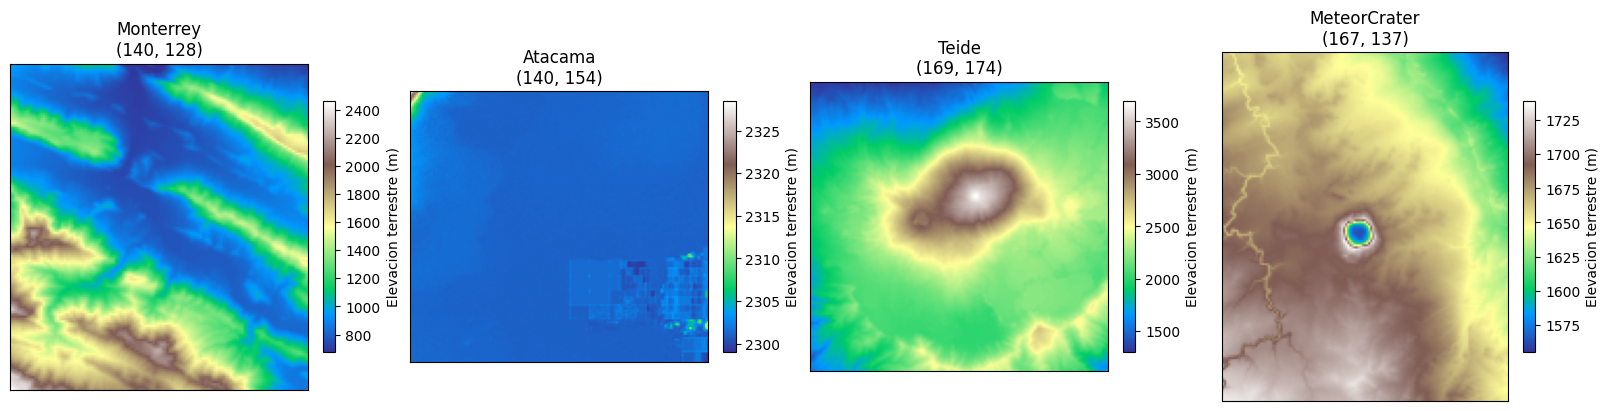

In [ ]:
fig, axs = plt.subplots(1, len(terrenos_tierra), figsize=(4*len(terrenos_tierra),4),
                        squeeze=False, constrained_layout=True)
for ax, (nombre,d) in zip(axs[0], terrenos_tierra.items()):
    im=ax.imshow(d['H'], cmap='terrain')
    ax.set_title(f'{nombre}\n{d["H"].shape}')
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im,ax=ax,shrink=.72,label='Elevacion terrestre (m)')
plt.show()

## PASO 8 — URLs oficiales y descarga/lectura AUTOMÁTICA (sin Drive)

**Cambio principal para el equipo:** las rutas ya no apuntan a archivos privados. Se usan las dos URLs públicas de NASA y DLR, exactamente el mismo producto para todos. Primero intentaremos lectura remota de bloques (sin descargar todo). Solo si falla, se descargará el GeoTIFF automáticamente a `/content/`. Si el tamaño supera el límite de seguridad, la celda explica cómo aumentarlo de manera explícita; no se generan datos falsos.

- NASA: https://pgda.gsfc.nasa.gov/products/90
- DLR/ESA: https://hrscteam.dlr.de/public/data/regionaldtms.php


In [ ]:
# PASO 8 — CONFIGURACIÓN AUTOMÁTICA DE FUENTES
# No requiere usuario, archivos, contraseña ni Google Drive.

URL_LUNA = 'https://pgda.gsfc.nasa.gov/data/LOLA_20mpp/LDEM_80S_80MPP_ADJ.TIF'
URL_MARTE = 'https://hrscteam.dlr.de/public/data/HMC30/MC11E/HMC_11E10_da5.tif'

# No usar el archivo completo si funciona la lectura remota por bloques.
INTENTAR_LECTURA_REMOTA = True

# Solo se usa si la lectura remota falla y hay que descargar el archivo entero.
# HRSC puede pesar cientos de MB o varios GB. Se aborta antes de agotarse
# el almacenamiento si el servidor anuncia un tamaño mayor al límite.
MAX_DESCARGA_GB = 5.0

# Guardamos el RECORTE procesado, no el DEM global/regional completo.
BORRAR_COMPLETOS_DESPUES_DE_RECORTE = True

# Opcional: si se necesita ejecutar sin Marte por problemas temporales del
# servidor DLR, cambiar a False y se continuará con Luna, indicando el fallo.
REQUERIR_MARTE = True

print('Fuentes configuradas. No se requiere Google Drive.')
print('Luna: NASA LOLA 80 m/px')
print('Marte: DLR/ESA HRSC DTM da5 50 m/px')


Fuentes configuradas. No se requiere Google Drive.
Luna: NASA LOLA 80 m/px
Marte: DLR/ESA HRSC DTM da5 50 m/px


## PASO 9 — Descargar si hace falta, recortar y validar los DEM planetarios

La función primero intenta **lectura remota por bloques**. Esto funciona especialmente bien con el producto LOLA, que NASA publica como Cloud Optimized GeoTIFF. Para HRSC, el éxito depende de que DLR permita solicitudes parciales y de la organización interna del TIFF; si no funciona, el notebook hace la descarga completa automáticamente. **No simulará** datos si ocurre un error. Al terminar, guarda GeoTIFFs locales pequeños con la resolución común de 80 m/px.

Si Colab se reinicia, basta con ejecutar el notebook de nuevo: se descargan o recuperan los datos para esa sesión.


In [ ]:
# PASO 9 — FUNCIONES DE LECTURA REMOTA, DESCARGA Y RECORTE
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from rasterio.windows import Window
from tqdm.auto import tqdm

# Datos del DEM original se leen siempre en unidades físicas correctas.
# NO asignamos EPSG terrestre a archivos planetarios.

def verificar_dem(src, nombre):
    if src.count != 1:
        raise ValueError(f'{nombre}: se necesita DEM de elevacion de 1 banda, no imagen RGB.')
    if src.crs is None or not src.crs.is_projected:
        raise ValueError(f'{nombre}: GeoTIFF sin proyeccion metrico-planetaria reconocible: CRS={src.crs}')
    try:
        unidad, factor = src.crs.linear_units_factor
    except Exception as e:
        raise ValueError(f'{nombre}: no se pudo leer la unidad proyectada del CRS') from e
    if not np.isclose(factor, 1.0, rtol=1e-4):
        raise ValueError(f'{nombre}: sus unidades no son metros ({unidad}; factor={factor}).')
    if abs(src.transform.b)>1e-9 or abs(src.transform.d)>1e-9:
        raise ValueError(f'{nombre}: TIFF rotado. Se requiere remuestreo geoespacial previo.')
    rx,ry=abs(src.transform.a),abs(src.transform.e)
    if max(rx,ry) > RES_M*1.10:
        raise ValueError(f'{nombre}: pixel fuente {rx:.1f}x{ry:.1f} m, demasiado grueso para 80 m. No se inventa detalle.')
    return rx,ry


def leer_recorte_desde_src(src, nombre, lado_m=15000.0):
    rx,ry=verificar_dem(src,nombre)
    cols=min(int(np.ceil(lado_m/rx)),src.width)
    rows=min(int(np.ceil(lado_m/ry)),src.height)
    if cols*rx < TAM_PIX*RES_M or rows*ry < TAM_PIX*RES_M:
        raise ValueError(f'{nombre}: el producto no cubre ni un parche completo.')

    # La primera ventana contiene el centro; otras permiten esquivar NoData.
    posiciones=[(.5,.5),(.25,.25),(.25,.75),(.75,.25),(.75,.75),(.5,.25),(.5,.75)]
    opciones=[]
    for px,py in posiciones:
        c=int((src.width-cols)*px); r=int((src.height-rows)*py)
        w=Window(c,r,cols,rows)
        nx=max(1,int(round(cols*rx/RES_M)))
        ny=max(1,int(round(rows*ry/RES_M)))
        # Remuestreo: promediado sobre un bloque cuando se reduce resolucion.
        H=src.read(1,window=w,out_shape=(ny,nx),masked=True,
                   resampling=Resampling.average).astype('float32').filled(np.nan)
        cobertura=np.isfinite(H).mean()
        if cobertura >= COBERTURA_MIN:
            opciones.append((np.nanstd(H),H,w,cobertura))
    if not opciones:
        raise RuntimeError(f'{nombre}: 7 recortes probados y ninguno supera cobertura {COBERTURA_MIN:.0%}.')

    relieve,H,w,cob=max(opciones,key=lambda a:a[0])
    tr=src.window_transform(w)*rasterio.Affine.scale(w.width/H.shape[1],w.height/H.shape[0])
    dx,dy=abs(tr.a),abs(tr.e)
    if abs(dx-RES_M)>3 or abs(dy-RES_M)>3:
        print(f'ADVERTENCIA: {nombre}, resolucion efectiva {dx:.2f}x{dy:.2f} m')
    salida=SALIDAS/f'{nombre.lower()}_recorte_80m.tif'
    with rasterio.open(salida,'w',driver='GTiff',height=H.shape[0],width=H.shape[1],
                       count=1,dtype='float32',crs=src.crs,transform=tr,
                       nodata=np.nan,compress='deflate') as dst:
        dst.write(H,1)
    return {'nombre':nombre,'cuerpo':nombre,'H':H,'transform':tr,
            'crs':src.crs,'dx':dx,'dy':dy,'ruta':str(salida),
            'cobertura':float(cob),'desv_elevacion':float(relieve)}


def descargar_con_reanudacion(url, destino, max_gb=5.0):
    destino=Path(destino)
    tmp=destino.with_suffix(destino.suffix+'.part')
    if destino.exists():
        try:
            with rasterio.open(destino) as prueba:
                if prueba.count==1:
                    print('Archivo local en cache:',destino)
                    return destino
        except Exception:
            destino.unlink(missing_ok=True)
    sesion=requests.Session()
    retry=Retry(total=3,backoff_factor=1,status_forcelist=[429,500,502,503,504],
                allowed_methods=['GET','HEAD'])
    sesion.mount('https://',HTTPAdapter(max_retries=retry))
    # HEAD es opcional. Algunos servidores no envian Content-Length.
    try:
        h=sesion.head(url,timeout=(15,30),allow_redirects=True)
        if h.ok and h.headers.get('Content-Length'):
            size=int(h.headers['Content-Length'])
            print('Tamaño del DEM remoto:',round(size/1e9,2),'GB')
            if size > max_gb*1e9:
                raise RuntimeError(
                    f'El DEM ocupa {size/1e9:.2f} GB, supera el limite {max_gb} GB. '
                    'Elige un DTM regional mas pequeno o ajusta MAX_DESCARGA_GB con almacenamiento suficiente.'
                )
    except requests.RequestException as ex:
        print('HEAD no disponible; el tamaño se revisara durante la descarga:',str(ex)[:100])

    offset=tmp.stat().st_size if tmp.exists() else 0
    encabezados={'Range':f'bytes={offset}-'} if offset else {}
    with sesion.get(url,stream=True,headers=encabezados,timeout=(20,120),allow_redirects=True) as resp:
        resp.raise_for_status()
        append=bool(offset and resp.status_code==206)
        if not append: offset=0
        n=resp.headers.get('Content-Length')
        total=(offset+int(n)) if n and n.isdigit() else None
        if total is not None and total > max_gb*1e9:
            raise RuntimeError(f'DEM anunciado de {total/1e9:.2f} GB supera {max_gb} GB permitidos.')
        print('Descargando GeoTIFF completo de fuente oficial (puede ser pesado):',url)
        with open(tmp,'ab' if append else 'wb') as f, tqdm(total=total,initial=offset,unit='B',unit_scale=True) as pbar:
            for bloque in resp.iter_content(chunk_size=1024*1024):
                if not bloque: continue
                f.write(bloque);pbar.update(len(bloque))
                if f.tell()>max_gb*1e9:
                    raise RuntimeError(f'Descarga detenida al superar {max_gb} GB; modifica el limite si tienes espacio.')
    tmp.replace(destino)
    return destino


def obtener_planetario_automatico(nombre, url):
    # 1. Preferir lectura por bloques remotos sobre el servidor de NASA o DLR.
    if INTENTAR_LECTURA_REMOTA and url.startswith(('http://','https://')):
        print(f'{nombre}: intentando leer recorte remoto sin descargar el TIFF completo...')
        try:
            with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR',
                              GDAL_HTTP_MAX_RETRY='2',GDAL_HTTP_RETRY_DELAY='1',
                              CPL_VSIL_CURL_ALLOWED_EXTENSIONS='.tif,.TIF'):
                with rasterio.open('/vsicurl/'+url) as src:
                    result=leer_recorte_desde_src(src,nombre)
            print(f'{nombre}: lectura por bloques OK, recorte local: {result["ruta"]}')
            return result
        except Exception as err:
            print(f'{nombre}: no hubo lectura remota parcial:',str(err)[:250])
            print('Intentaremos la descarga automatica completa como respaldo.')

    # 2. Si el servidor no permite lectura por bloques, bajar archivo original.
    ruta=SALIDAS/f'original_{nombre.lower()}.tif'
    ruta=descargar_con_reanudacion(url,ruta,MAX_DESCARGA_GB)
    try:
        with rasterio.open(ruta) as src:
            result=leer_recorte_desde_src(src,nombre)
    finally:
        if BORRAR_COMPLETOS_DESPUES_DE_RECORTE and ruta.exists():
            ruta.unlink()
            print(nombre,': eliminado TIFF completo, conservamos el recorte procesado')
    return result

print('Funciones de lectura automatica listas.')


Funciones de lectura automatica listas.


## PASO 10 — Obtener automáticamente Luna y Marte, comprobar y visualizar

No se requiere `files.upload()` ni `drive.mount()`. La salida debe mostrar **Luna** y **Marte** si ambos servidores permitieron el acceso. Si no puede obtenerse Marte, se informa el error específico en vez de continuar silenciosamente con datos faltantes.


Luna: intentando leer recorte remoto sin descargar el TIFF completo...
Luna: lectura por bloques OK, recorte local: /content/HackNASA_salidas/luna_recorte_80m.tif
Luna: (188, 188) | dx=80.0 m | dy=80.0 m | validos=100.0%
Marte: intentando leer recorte remoto sin descargar el TIFF completo...
Marte: lectura por bloques OK, recorte local: /content/HackNASA_salidas/marte_recorte_80m.tif
Marte: (188, 188) | dx=79.8 m | dy=79.8 m | validos=100.0%


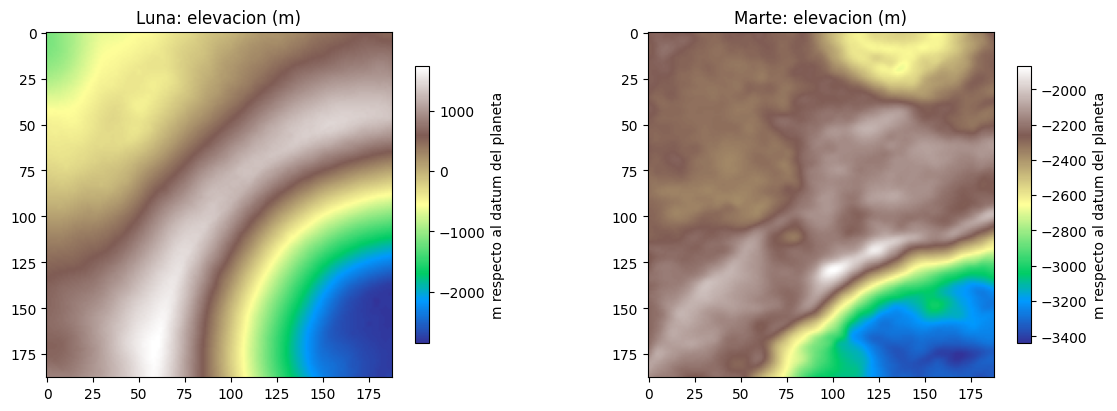

In [ ]:
# PASO 10 — CARGA AUTOMATICA DE LUNA Y MARTE
planetas={}
fuentes={'Luna':URL_LUNA,'Marte':URL_MARTE}
errores_planetarios={}

for nombre,url in fuentes.items():
    try:
        planetas[nombre]=obtener_planetario_automatico(nombre,url)
        d=planetas[nombre]
        print(f'{nombre}: {d["H"].shape} | dx={d["dx"]:.1f} m | dy={d["dy"]:.1f} m | validos={d["cobertura"]:.1%}')
    except Exception as exc:
        errores_planetarios[nombre]=str(exc)
        print(f'ERROR DE OBTENCION {nombre}: {exc}')

if not planetas:
    raise RuntimeError('No se pudo leer ninguno de los DEM planetarios desde sus servidores oficiales. '+str(errores_planetarios))
if REQUERIR_MARTE and 'Marte' not in planetas:
    raise RuntimeError('Marte no pudo obtenerse automaticamente. Revisa el error de DLR indicado arriba. '+str(errores_planetarios.get('Marte','')))

fig,axs=plt.subplots(1,len(planetas),figsize=(6*len(planetas),4),squeeze=False,constrained_layout=True)
for ax,(nombre,d) in zip(axs[0],planetas.items()):
    im=ax.imshow(d['H'],cmap='terrain');ax.set_title(f'{nombre}: elevacion (m)')
    fig.colorbar(im,ax=ax,shrink=.8,label='m respecto al datum del planeta')
plt.show()


In [ ]:

# PASO 10B - CORREGIR ESCALA ESPACIAL DEL DEM MARCIANO

import numpy as np
import rasterio

from rasterio.crs import CRS
from rasterio.warp import reproject, transform_bounds, Resampling
from rasterio.transform import from_origin

# Radio de referencia de la esfera marciana utilizada
# en el CRS del archivo HRSC seleccionado
R_MARTE = 3396000.0

marte = planetas["Marte"]

# Centro del recorte en coordenadas de la proyeccion
alto, ancho = marte["H"].shape

xc, yc = marte["transform"] * (
    ancho / 2,
    alto / 2
)

# El CRS original es equirectangular con paralelo estandar 0.
# En ese caso, y = R * latitud_en_radianes
lat_centro = np.degrees(yc / R_MARTE)

# Nueva proyeccion equirectangular ajustada
# al paralelo central del recorte
crs_local = CRS.from_proj4(
    f"+proj=eqc "
    f"+lat_ts={lat_centro:.10f} "
    f"+lon_0=0 "
    f"+R={R_MARTE} "
    f"+units=m +no_defs +type=crs"
)

# Transformar limites a la proyeccion local
xmin, ymin, xmax, ymax = transform_bounds(
    marte["crs"],
    crs_local,
    *rasterio.transform.array_bounds(
        alto, ancho, marte["transform"]
    ),
    densify_pts=21
)

# Crear cuadricula de 80 metros
res = 80.0

nuevo_ancho = int(np.ceil((xmax - xmin) / res))
nuevo_alto = int(np.ceil((ymax - ymin) / res))

nueva_transform = from_origin(
    xmin, ymax, res, res
)

H_corregida = np.full(
    (nuevo_alto, nuevo_ancho),
    np.nan,
    dtype=np.float32
)

# Reproyectar elevaciones
reproject(
    source=marte["H"].astype(np.float32),
    destination=H_corregida,
    src_transform=marte["transform"],
    src_crs=marte["crs"],
    src_nodata=np.nan,
    dst_transform=nueva_transform,
    dst_crs=crs_local,
    dst_nodata=np.nan,
    resampling=Resampling.bilinear
)

# Actualizar datos para los pasos posteriores
marte.update({
    "H": H_corregida,
    "transform": nueva_transform,
    "crs": crs_local,
    "dx": res,
    "dy": res,
    "cobertura": float(
        np.isfinite(H_corregida).mean()
    )
})

# Guardar GeoTIFF corregido
ruta_corregida = SALIDAS / "marte_recorte_80m.tif"

with rasterio.open(
    ruta_corregida,
    "w",
    driver="GTiff",
    height=nuevo_alto,
    width=nuevo_ancho,
    count=1,
    dtype="float32",
    crs=crs_local,
    transform=nueva_transform,
    nodata=np.nan,
    compress="deflate"
) as dst:
    dst.write(H_corregida, 1)

marte["ruta"] = str(ruta_corregida)

print("DEM MARCIANO REPROYECTADO")
print("Latitud central:", round(lat_centro, 4))
print("Dimensiones:", H_corregida.shape)
print("Resolucion:", res, "m/pixel")
print(
    "Cobertura:",
    round(np.isfinite(H_corregida).mean() * 100, 2),
    "%"
)
print("Archivo guardado:", ruta_corregida)


DEM MARCIANO REPROYECTADO
Latitud central: 26.1876
Dimensiones: (188, 169)
Resolucion: 80.0 m/pixel
Cobertura: 98.88 %
Archivo guardado: /content/HackNASA_salidas/marte_recorte_80m.tif


## PASO 11 — Diagnóstico de resolución y validez planetaria

No comparamos imágenes en colores ni DEMs expresados en grados de latitud.

In [ ]:
for nombre,d in planetas.items():
    z=d['H']
    print(nombre, 'malla=',z.shape, 'dx=',round(d['dx'],2),
          'dy=',round(d['dy'],2), 'cobertura=',round(np.isfinite(z).mean()*100,1),'%')
    print('Rango de elevación:',round(np.nanmin(z),2),round(np.nanmax(z),2),'m')
assert planetas, 'Sube al menos un DEM LOLA o HRSC'

Luna malla= (188, 188) dx= 80.0 dy= 80.0 cobertura= 100.0 %
Rango de elevación: -2843.63 1736.76 m
Marte malla= (188, 169) dx= 80.0 dy= 80.0 cobertura= 98.9 %
Rango de elevación: -3434.97 -1870.52 m


## PASO 12 — Construir una pirámide multiescala por terreno

Pirámide grueso → fino; a diferencia del primer DEM de Monterrey, usamos factores 4, 2 y 1 para no perder demasiada información en parches pequeños.

In [ ]:
from rasterio.transform import from_origin

def crear_piramide(d, factores=(4,2,1)):
    z=d['H']; salida={}
    for f in factores:
        alto=max(1,int(np.ceil(z.shape[0]/f)))
        ancho=max(1,int(np.ceil(z.shape[1]/f)))
        nuevo=np.full((alto,ancho),np.nan,dtype='float32')
        tr=d['transform']*rasterio.Affine.scale(z.shape[1]/ancho,z.shape[0]/alto)
        reproject(source=z,destination=nuevo,src_transform=d['transform'],src_crs=d['crs'],src_nodata=np.nan,
                  dst_transform=tr,dst_crs=d['crs'],dst_nodata=np.nan,resampling=Resampling.average)
        salida[f]={'H':nuevo,'dx':abs(tr.a),'dy':abs(tr.e),'transform':tr}
    return salida

TERRENOS={**terrenos_tierra,**planetas}
piramides={nombre:crear_piramide(d) for nombre,d in TERRENOS.items()}
for nombre,p in piramides.items():
    print(nombre, {f:(d['H'].shape,round(d['dx'],1)) for f,d in p.items()})

Monterrey {4: ((35, 32), 320.0), 2: ((70, 64), 160.0), 1: ((140, 128), 80.0)}
Atacama {4: ((35, 39), 315.9), 2: ((70, 77), 160.0), 1: ((140, 154), 80.0)}
Teide {4: ((43, 44), 316.4), 2: ((85, 87), 160.0), 1: ((169, 174), 80.0)}
MeteorCrater {4: ((42, 35), 313.1), 2: ((84, 69), 158.8), 1: ((167, 137), 80.0)}
Luna {4: ((47, 47), 320.0), 2: ((94, 94), 160.0), 1: ((188, 188), 80.0)}
Marte {4: ((47, 43), 314.4), 2: ((94, 85), 159.1), 1: ((188, 169), 80.0)}


## PASO 13 — Visualizar y validar las tres escalas

Una misma área debe mantener la estructura general en todas las escalas.

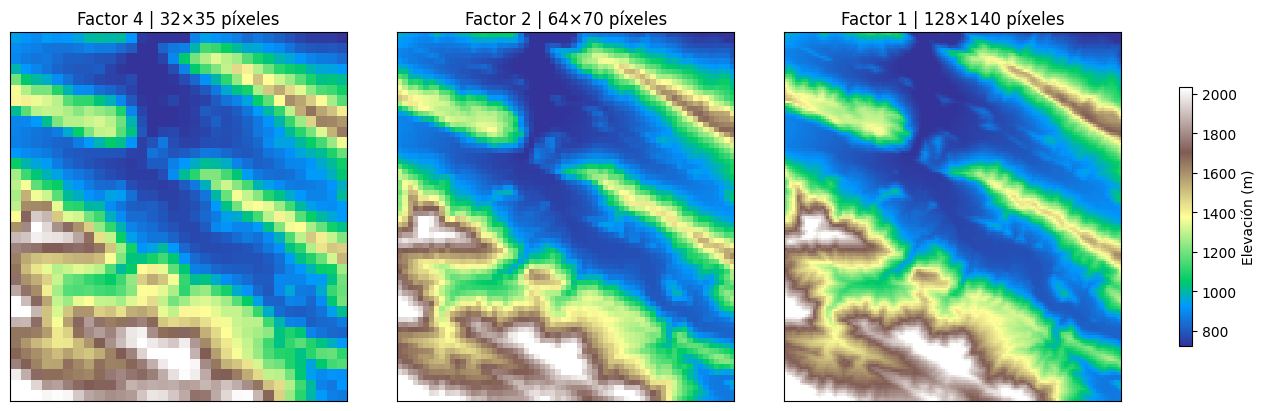

In [ ]:
ejemplo_nombre=next(iter(terrenos_tierra))
fig,axs=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
capas=piramides[ejemplo_nombre]
lim=np.nanpercentile(capas[1]['H'],[2,98])
for ax,f in zip(axs,[4,2,1]):
    z=capas[f]['H']
    im=ax.imshow(z,cmap='terrain',vmin=lim[0],vmax=lim[1],interpolation='nearest')
    ax.set_title(f'Factor {f} | {z.shape[1]}×{z.shape[0]} píxeles')
    ax.set_xticks([]);ax.set_yticks([])
fig.colorbar(im,ax=axs,label='Elevación (m)',shrink=.7)
plt.show()

## PASO 14 — Calcular gradiente, pendiente, curvatura y rugosidad

La pendiente usa derivadas en m/m. La curvatura es un laplaciano aproximado; la rugosidad elimina un plano local.

In [ ]:
def caracteristicas_dem(H,dx,dy,ventana=5):
    z=np.asarray(H,dtype='float64')
    valid=np.isfinite(z)
    if not valid.any() or min(z.shape)<ventana: raise ValueError('DEM invalido o demasiado pequeño')
    if not valid.all():
        inds=ndi.distance_transform_edt(~valid,return_indices=True,return_distances=False)
        z0=z[tuple(inds)]
    else: z0=z.copy()
    suave=ndi.gaussian_filter(z0,1,mode='reflect')
    gy,gx=np.gradient(suave,dy,dx)
    g=np.hypot(gx,gy)
    p=np.degrees(np.arctan(g))
    cur=(np.gradient(np.gradient(suave,dx,axis=1),dx,axis=1)
         +np.gradient(np.gradient(suave,dy,axis=0),dy,axis=0))
    r=ventana//2
    yy,xx=np.mgrid[-r:r+1,-r:r+1]
    xx=xx*dx; yy=yy*dy
    n=ventana**2
    vx=np.mean(xx**2); vy=np.mean(yy**2)
    mz=ndi.uniform_filter(z0,ventana,mode='reflect')
    mz2=ndi.uniform_filter(z0*z0,ventana,mode='reflect')
    covx=ndi.correlate(z0,xx/n,mode='reflect')
    covy=ndi.correlate(z0,yy/n,mode='reflect')
    res2=mz2-mz*mz-(covx*covx/vx)-(covy*covy/vy)
    rug=np.sqrt(np.maximum(res2,0))
    cobertura=ndi.uniform_filter(valid.astype(float),ventana,mode='constant',cval=0)
    mascara=cobertura>.999
    for a in (g,p,cur,rug): a[~mascara]=np.nan
    return {'gradiente':g,'pendiente':p,'curvatura':cur,'rugosidad':rug}

## PASO 15 — Probar las fórmulas con un terreno artificial

Comprobación matemática: un plano sin irregularidades debe tener rugosidad cercana a cero.

In [ ]:
# Sanidad: un plano inclinado tiene rugosidad casi nula fuera de bordes
Y,X=np.mgrid[:40,:40]
assert np.nanmedian(caracteristicas_dem(1000+X*.8+Y*.4,80,80)['rugosidad'])<1e-3
print('Prueba de plano: OK')

Prueba de plano: OK


## PASO 16 — Calcular características de todos los DEMs

Se reutiliza el mismo algoritmo para Tierra, Luna y Marte.

In [ ]:
TERRENOS={**terrenos_tierra,**planetas}
for nombre,d in TERRENOS.items():
    d.update(caracteristicas_dem(d['H'],d['dx'],d['dy']))
    print(nombre,'pendiente mediana:',round(np.nanmedian(d['pendiente']),2),
          '| rugosidad mediana:',round(np.nanmedian(d['rugosidad']),2))

Monterrey pendiente mediana: 21.21 | rugosidad mediana: 16.31
Atacama pendiente mediana: 0.01 | rugosidad mediana: 0.04
Teide pendiente mediana: 12.3 | rugosidad mediana: 6.72
MeteorCrater pendiente mediana: 0.84 | rugosidad mediana: 0.63
Luna pendiente mediana: 17.88 | rugosidad mediana: 1.94
Marte pendiente mediana: 5.4 | rugosidad mediana: 2.33


## PASO 17 — Mostrar mapas de pendiente, curvatura y rugosidad

Mapas originales con unidades físicas; no son únicamente imágenes RGB.

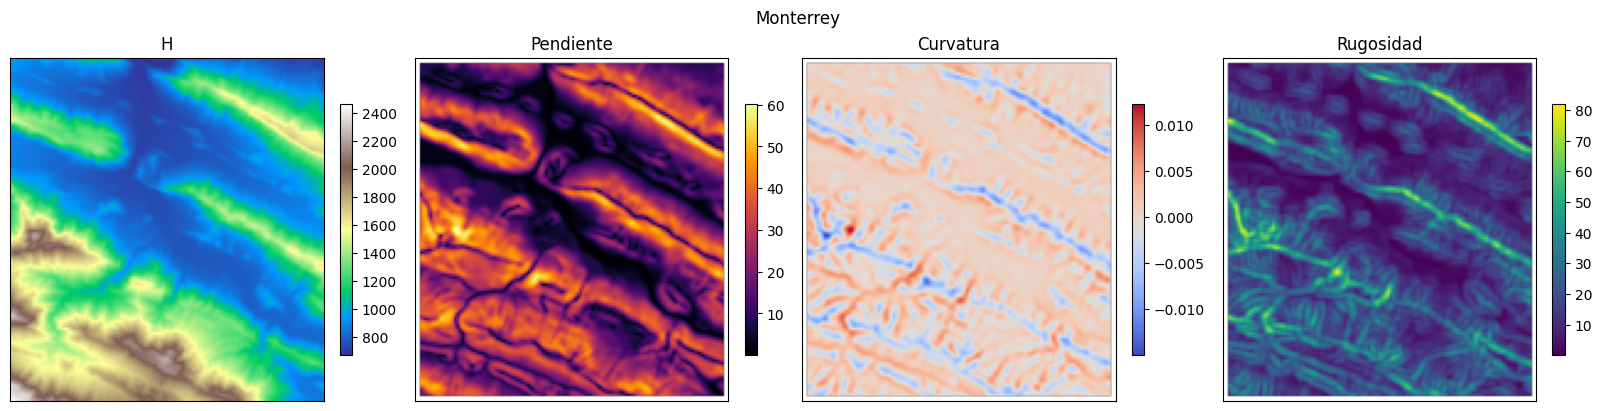

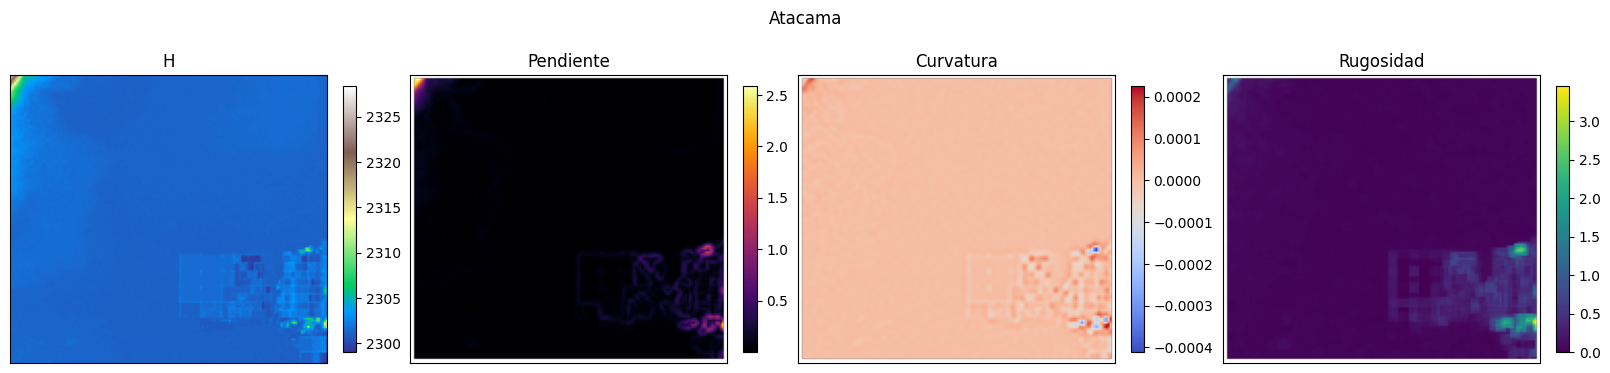

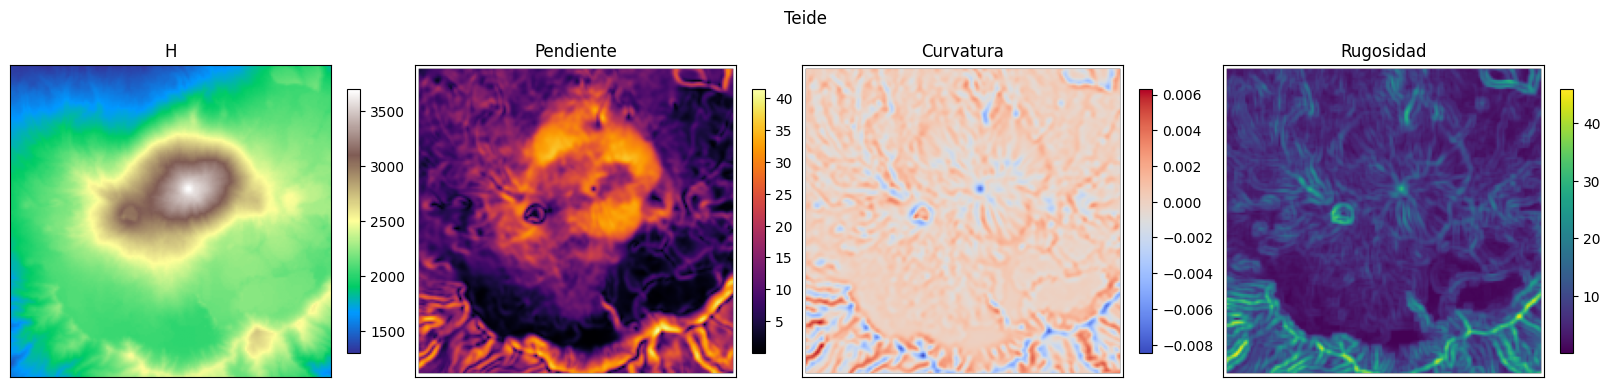

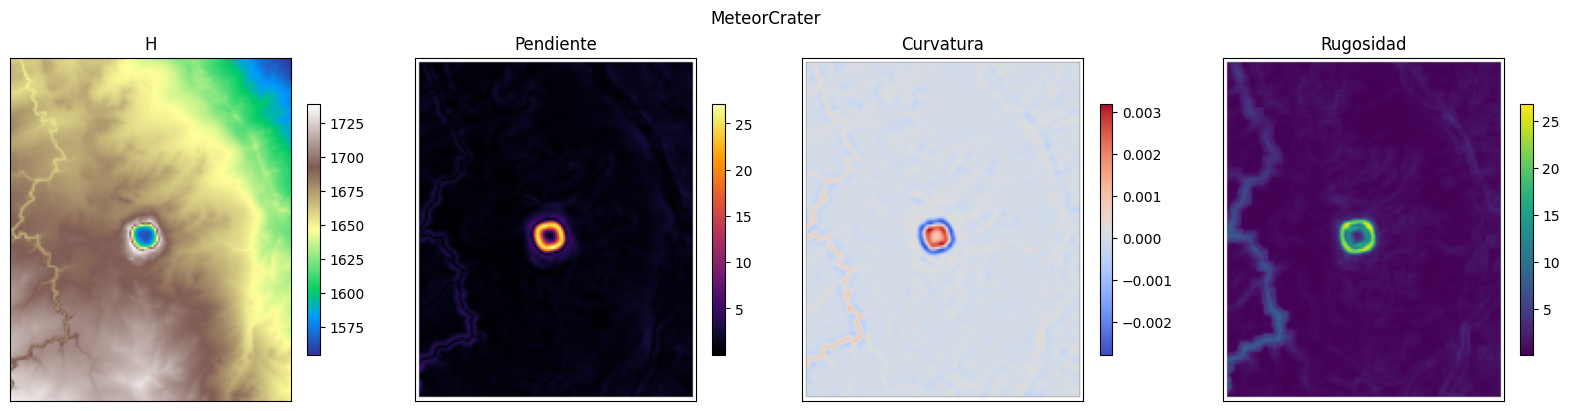

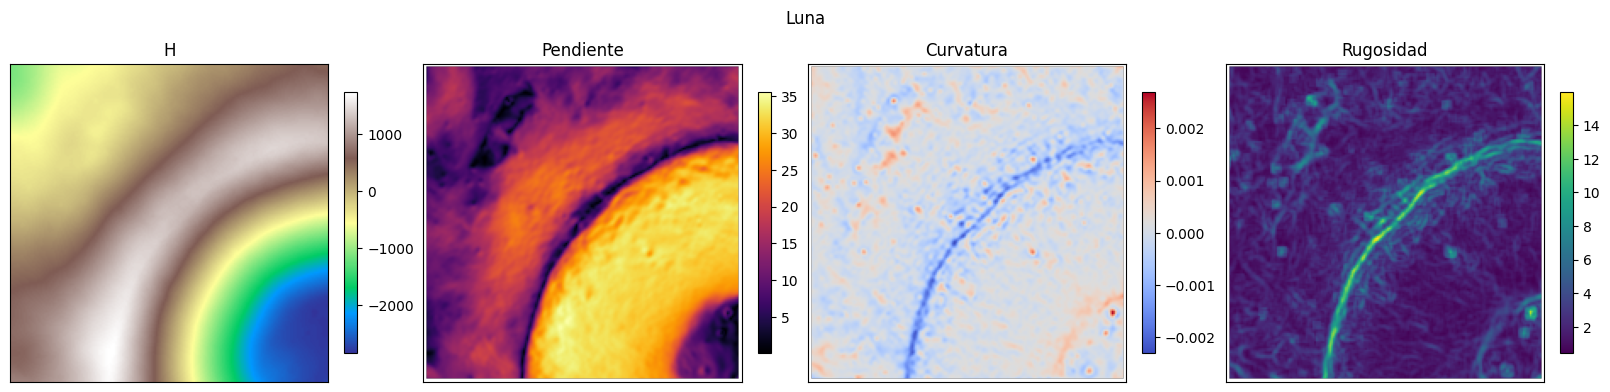

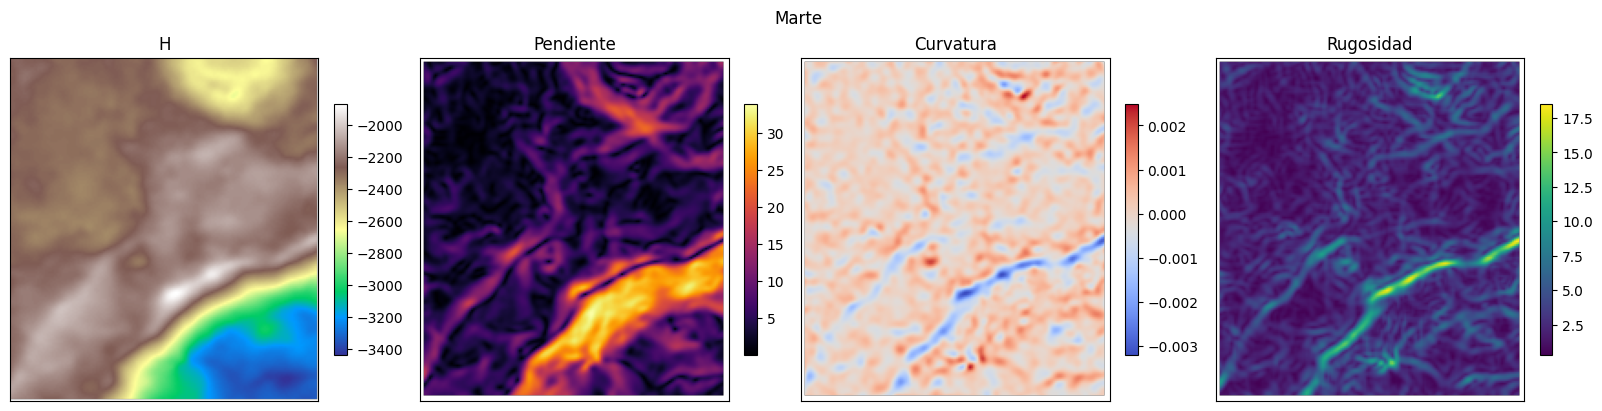

In [ ]:
for nombre,d in TERRENOS.items():
    fig,axs=plt.subplots(1,4,figsize=(16,4),constrained_layout=True)
    for ax,key,cmap in zip(axs,['H','pendiente','curvatura','rugosidad'],['terrain','inferno','coolwarm','viridis']):
        im=ax.imshow(d[key],cmap=cmap)
        ax.set_title(key.capitalize());ax.set_xticks([]);ax.set_yticks([])
        fig.colorbar(im,ax=ax,shrink=.73)
    fig.suptitle(nombre)
    plt.show()

## PASO 18 — Generar máscaras continuas normalizadas

Máscaras normalizadas para visualización por terreno; para comparar físicamente conservaremos los valores sin normalizar.

In [ ]:
for nombre,d in TERRENOS.items():
    C=d['curvatura'];R=d['rugosidad'];
    lc=np.nanpercentile(np.abs(C),98); lr=np.nanpercentile(R,98)
    d['curvatura_norm']=np.clip(C/max(lc,1e-12),-1,1)
    d['rugosidad_norm']=np.clip(R/max(lr,1e-12),0,1)
    d['mascara_valida']=np.isfinite(C)&np.isfinite(R)&np.isfinite(d['pendiente'])
    print(nombre,'cobertura util',round(d['mascara_valida'].mean()*100,1),'%')

Monterrey cobertura util 94.1 %
Atacama cobertura util 94.6 %
Teide cobertura util 95.4 %
MeteorCrater cobertura util 94.8 %
Luna cobertura util 95.8 %
Marte cobertura util 94.5 %


## PASO 19 — Visualizar las máscaras normalizadas

No usar las máscaras normalizadas individualmente por cuerpo como si fueran unidades físicas equivalentes.

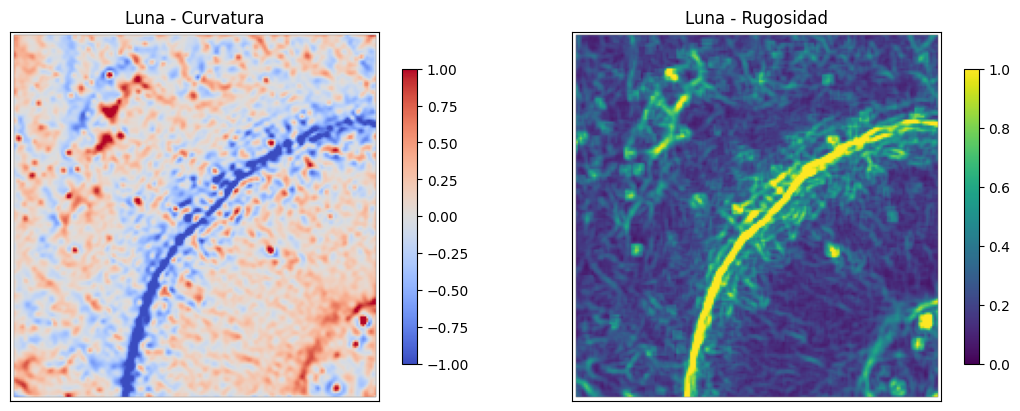

In [ ]:
ejemplo=next(iter(planetas))
d=planetas[ejemplo]
fig,axs=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,z,cmap,titulo,vmin,vmax in [
    (axs[0],d['curvatura_norm'],'coolwarm','Curvatura',-1,1),
    (axs[1],d['rugosidad_norm'],'viridis','Rugosidad',0,1)]:
    im=ax.imshow(z,cmap=cmap,vmin=vmin,vmax=vmax)
    ax.set_title(ejemplo+' - '+titulo); ax.set_xticks([]);ax.set_yticks([])
    fig.colorbar(im,ax=ax,shrink=.8)
plt.show()

## PASO 20 — Definir parches y ocho descriptores por región

Un parche mantiene el mismo tamaño físico a 80 m/píxel, independientemente del planeta.

In [ ]:
def crear_parches(d,prefijo):
    registros=[]
    H,P,C,R=(d[k] for k in ('H','pendiente','curvatura','rugosidad'))
    for i in range(0,H.shape[0]-TAM_PIX+1,SALTO_PIX):
        for j in range(0,H.shape[1]-TAM_PIX+1,SALTO_PIX):
            s=np.s_[i:i+TAM_PIX,j:j+TAM_PIX]
            p,c,r=P[s],C[s],R[s]
            val=np.isfinite(p)&np.isfinite(c)&np.isfinite(r)
            if val.mean()<COBERTURA_MIN: continue
            a=p[val]; b=np.abs(c[val]); z=r[val]
            x,y=d['transform']*(j+TAM_PIX/2,i+TAM_PIX/2)
            registros.append({
                'parche_id':f'{prefijo}_{i:03d}_{j:03d}',
                'region':d['nombre'],'cuerpo':d['cuerpo'],
                'fila':i,'col':j,'x':float(x),'y':float(y),
                'crs':str(d['crs']),'cobertura':float(val.mean()),
                'pendiente_media':float(a.mean()),'pendiente_std':float(a.std()),
                'pendiente_p90':float(np.percentile(a,90)),
                'curvatura_abs_media':float(b.mean()),
                'curvatura_abs_p90':float(np.percentile(b,90)),
                'rugosidad_mediana':float(np.median(z)),
                'rugosidad_p90':float(np.percentile(z,90)),
                'rugosidad_std':float(z.std())
            })
    return pd.DataFrame(registros)

## PASO 21 — Extraer vectores de todos los terrenos

Cada fila contiene ID, cuerpo, región, coordenadas, cobertura y ocho rasgos topográficos.

In [ ]:
partes=[]
for nombre,d in terrenos_tierra.items():
    t=crear_parches(d,'T_'+nombre)
    print('Tierra',nombre,len(t),'parches')
    if not t.empty: partes.append(t)
if not partes: raise RuntimeError('No hay parches terrestres validos; amplía las zonas')
tabla_tierra=pd.concat(partes,ignore_index=True)
tablas_planeta={nombre:crear_parches(d, 'L' if nombre=='Luna' else 'M') for nombre,d in planetas.items()}
for nombre,t in tablas_planeta.items():
    print(nombre,len(t),'parches')
    if t.empty: raise RuntimeError(f'{nombre} no genero parches; elige otra zona DEM')
display(tabla_tierra[['parche_id','region','pendiente_media','rugosidad_mediana']].head())

Tierra Monterrey 30 parches
Tierra Atacama 42 parches
Tierra Teide 56 parches
Tierra MeteorCrater 42 parches
Luna 64 parches
Marte 56 parches


,parche_id,region,pendiente_media,rugosidad_mediana
0,T_Monterrey_000_000,Monterrey,19.280768,14.501092
1,T_Monterrey_000_019,Monterrey,15.699038,10.991833
2,T_Monterrey_000_038,Monterrey,14.876353,10.312038
3,T_Monterrey_000_057,Monterrey,20.311575,13.228612
4,T_Monterrey_000_076,Monterrey,26.014498,12.560504


## PASO 22 — Validar parches, cobertura y coordenadas

Comprueba que los parches corresponden a zonas reales y tienen cobertura suficiente.

Tierra parches: 170 cobertura media: 0.984
Primeros IDs: ['T_Monterrey_000_000', 'T_Monterrey_000_019', 'T_Monterrey_000_038']
Luna parches: 64 cobertura media: 0.987
Primeros IDs: ['L_000_000', 'L_000_019', 'L_000_038']
Marte parches: 56 cobertura media: 0.986
Primeros IDs: ['M_000_000', 'M_000_019', 'M_000_038']


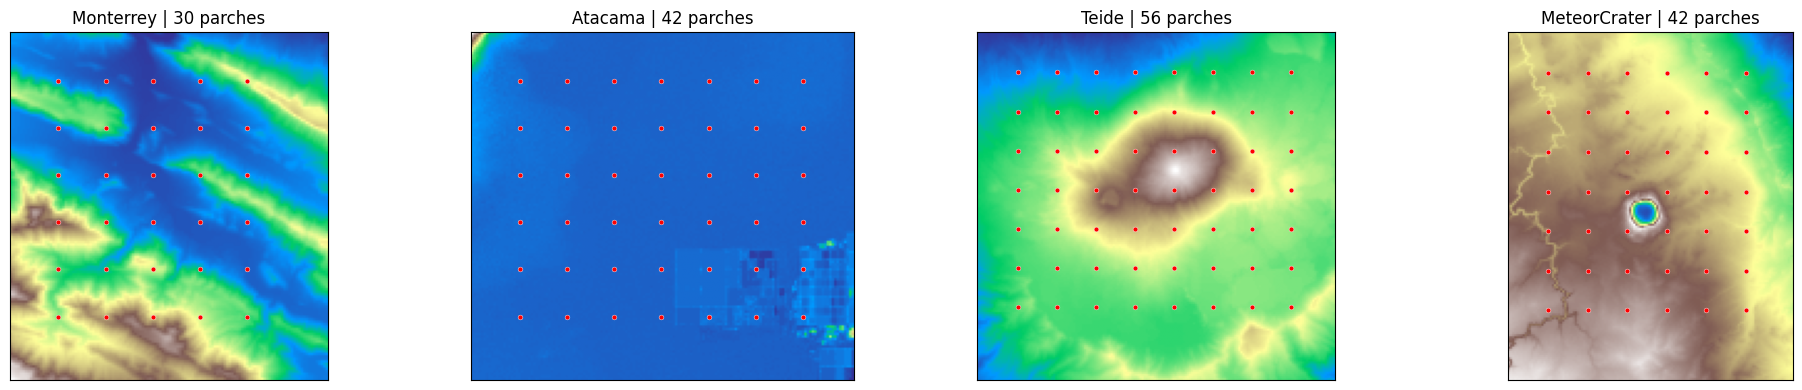

In [ ]:
for cuerpo, tabla in [('Tierra',tabla_tierra),*list(tablas_planeta.items())]:
    print(cuerpo,'parches:',len(tabla),'cobertura media:',round(tabla['cobertura'].mean(),3))
    print('Primeros IDs:',tabla['parche_id'].head(3).tolist())

fig,axs=plt.subplots(1,len(terrenos_tierra),figsize=(5*len(terrenos_tierra),4),squeeze=False)
for ax,(nombre,d) in zip(axs[0],terrenos_tierra.items()):
    ax.imshow(d['H'],cmap='terrain')
    t=tabla_tierra[tabla_tierra['region']==nombre]
    ax.scatter(t['col']+TAM_PIX/2,t['fila']+TAM_PIX/2,s=12,c='red',edgecolors='white',linewidths=.3)
    ax.set_title(f'{nombre} | {len(t)} parches');ax.set_xticks([]);ax.set_yticks([])
plt.tight_layout();plt.show()

## PASO 23 — Normalización común y pesos físicos iniciales

Se calculan la mediana y el IQR SOLO en la base terrestre y se aplican a ambos planetas; los pesos por familia suman 1.

In [ ]:
mediana=tabla_tierra[CARACTERISTICAS].median()
q25=tabla_tierra[CARACTERISTICAS].quantile(.25)
q75=tabla_tierra[CARACTERISTICAS].quantile(.75)
escala=(q75-q25).where((q75-q25)>1e-12,1.0)
X_tierra=(tabla_tierra[CARACTERISTICAS]-mediana)/escala
X_planeta={nombre:(t[CARACTERISTICAS]-mediana)/escala for nombre,t in tablas_planeta.items()}
# Igual peso total por familia: pendiente (3), curvatura (2), rugosidad (3)
pesos=pd.Series([1/9]*3+[1/6]*2+[1/9]*3,index=CARACTERISTICAS)
print('Base terrestre:',len(X_tierra),'vectores')
for n,x in X_planeta.items(): print(n,len(x),'vectores')

Base terrestre: 170 vectores
Luna 64 vectores
Marte 56 vectores


## PASO 24 — Primer ranking físico contra Tierra

Ranking usando únicamente pendiente/curvatura/rugosidad, sin considerar todavía cómo se organizan espacialmente.

In [ ]:
rankings_fisicos={}
referencias={}
for nombre,t in tablas_planeta.items():
    idx=(t['pendiente_media']-t['pendiente_media'].median()).abs().idxmin()
    referencias[nombre]=idx
    delta=X_tierra.sub(X_planeta[nombre].loc[idx],axis=1).pow(2)
    dist=delta.mul(pesos,axis=1).sum(axis=1)/pesos.sum()
    ranking=tabla_tierra[['parche_id','region','fila','col']].copy()
    ranking['distancia_fisica']=dist.to_numpy()
    ranking=ranking.sort_values('distancia_fisica').reset_index(drop=True)
    rankings_fisicos[nombre]=ranking
    print(nombre,'referencia:',t.loc[idx,'parche_id'])
    display(ranking.head(5).round(4))

Luna referencia: L_038_095


,parche_id,region,fila,col,distancia_fisica
0,T_Teide_095_038,Teide,95,38,0.0313
1,T_Teide_095_057,Teide,95,57,0.0327
2,T_Teide_095_076,Teide,95,76,0.0521
3,T_Teide_076_019,Teide,76,19,0.0594
4,T_Teide_000_038,Teide,0,38,0.0689


Marte referencia: M_114_019


,parche_id,region,fila,col,distancia_fisica
0,T_Teide_019_133,Teide,19,133,0.0195
1,T_Teide_095_114,Teide,95,114,0.0327
2,T_Teide_095_038,Teide,95,38,0.0460
3,T_Teide_114_057,Teide,114,57,0.0470
4,T_MeteorCrater_114_000,MeteorCrater,114,0,0.0522


## PASO 25 — Analizar contribuciones de las ocho características

Diagnóstico para comprender qué variables alejan o acercan cada par de terrenos.

,pendiente_media,pendiente_std,pendiente_p90,curvatura_abs_media,curvatura_abs_p90,rugosidad_mediana,rugosidad_p90,rugosidad_std
parche_id,,,,,,,,
T_Teide_095_038,0.0234,0.0007,0.0009,0.0003,0.0001,0.0050,0.0000,0.0010
T_Teide_095_057,0.0117,0.0026,0.0012,0.0034,0.0007,0.0113,0.0003,0.0015
T_Teide_095_076,0.0185,0.0012,0.0022,0.0098,0.0030,0.0130,0.0014,0.0031


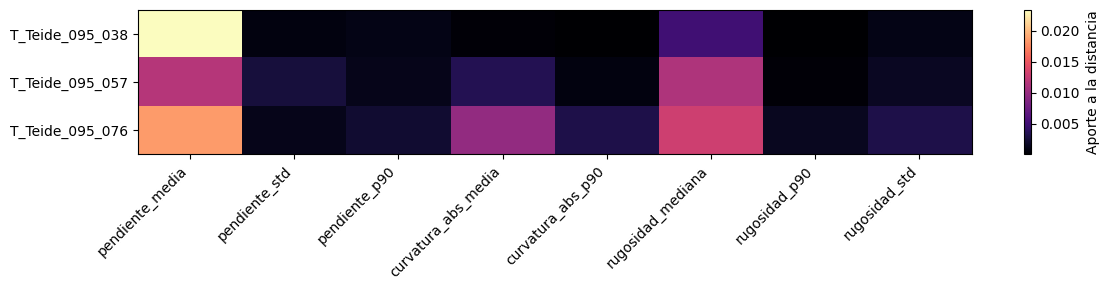

In [ ]:
nombre=next(iter(planetas)); idx=referencias[nombre]
seleccion=rankings_fisicos[nombre].head(3)
indices=tabla_tierra.index[tabla_tierra['parche_id'].isin(seleccion['parche_id'])]
contr=((X_tierra.loc[indices].sub(X_planeta[nombre].loc[idx],axis=1).pow(2))
       .mul(pesos,axis=1)/pesos.sum())
contr.index=tabla_tierra.loc[indices,'parche_id']
display(contr.round(4))
fig,ax=plt.subplots(figsize=(12,3))
im=ax.imshow(contr.values,cmap='magma',aspect='auto')
ax.set_xticks(range(len(CARACTERISTICAS)));ax.set_xticklabels(CARACTERISTICAS,rotation=45,ha='right')
ax.set_yticks(range(len(contr)));ax.set_yticklabels(contr.index)
fig.colorbar(im,ax=ax,label='Aporte a la distancia');plt.tight_layout();plt.show()

## PASO 26 — Extraer parches para comparación espacial

Convierte filas de la tabla en pequeños mapas de elevación reales.

In [ ]:
def parche(fila):
    d=TERRENOS[fila['region']]
    i,j=int(fila['fila']),int(fila['col'])
    return d['H'][i:i+TAM_PIX,j:j+TAM_PIX]

## PASO 27 — Eliminar la inclinación general (detrending)

Ajustamos un plano por mínimos cuadrados y lo restamos antes de comparar patrones locales.

In [ ]:
def sin_plano(z):
    z=np.asarray(z,dtype=float); v=np.isfinite(z)
    if v.mean()<COBERTURA_MIN: return None
    yy,xx=np.indices(z.shape)
    A=np.column_stack([xx[v],yy[v],np.ones(v.sum())])
    a,b,c=np.linalg.lstsq(A,z[v],rcond=None)[0]
    ret=z-(a*xx+b*yy+c); ret[~v]=np.nan
    return ret

## PASO 28 — Comparar formas con rotaciones de 0°, 90°, 180° y 270°

Correlación normalizada sobre elevación residual; no confundir correlación con porcentaje de similitud.

In [ ]:
def corr_forma(z1,z2):
    a,b=sin_plano(z1),sin_plano(z2)
    if a is None or b is None: return np.nan,np.nan
    def suav(z):
        v=np.isfinite(z)
        num=ndi.gaussian_filter(np.where(v,z,0),1)
        den=ndi.gaussian_filter(v.astype(float),1)
        zz=num/np.maximum(den,1e-12); zz[~v]=np.nan
        return zz
    a,b=suav(a),suav(b)
    mejor=(-np.inf,np.nan)
    for k in range(4):
        rot=np.rot90(b,k)
        v=np.isfinite(a)&np.isfinite(rot)
        if v.mean()<COBERTURA_MIN: continue
        aa=a[v]-a[v].mean(); bb=rot[v]-rot[v].mean()
        den=np.linalg.norm(aa)*np.linalg.norm(bb)
        if den<1e-12: continue
        rho=float(np.dot(aa,bb)/den)
        if rho>mejor[0]: mejor=(rho,k*90)
    return mejor if np.isfinite(mejor[0]) else (np.nan,np.nan)

## PASO 29 — Contrastar rankings físicos y geométricos

Este paso reproduce la comparación estadística frente a comparación de formas del proyecto anterior.

In [ ]:
comparaciones_independientes={}
for nombre,t in tablas_planeta.items():
    idx=referencias[nombre]
    ref=t.loc[idx]
    Href=parche(ref)
    filas=[]
    for _,f in tabla_tierra.iterrows():
        r,ang=corr_forma(Href,parche(f))
        filas.append({'parche_id':f['parche_id'],'region':f['region'],'corr_forma':r,'rotacion_grados':ang})
    df=pd.DataFrame(filas)
    fis=rankings_fisicos[nombre][['parche_id','distancia_fisica']]
    comparaciones_independientes[nombre]=df.merge(fis,on='parche_id')
    print('\n',nombre,'TOP físico:')
    display(comparaciones_independientes[nombre].nsmallest(5,'distancia_fisica'))
    print('TOP geométrico:')
    display(comparaciones_independientes[nombre].nlargest(5,'corr_forma'))


 Luna TOP físico:


,parche_id,region,corr_forma,rotacion_grados,distancia_fisica
114,T_Teide_095_038,Teide,0.310524,180,0.031300
115,T_Teide_095_057,Teide,0.119651,270,0.032676
116,T_Teide_095_076,Teide,0.651801,270,0.052076
105,T_Teide_076_019,Teide,0.691325,0,0.059387
74,T_Teide_000_038,Teide,-0.073768,270,0.068919


TOP geométrico:


,parche_id,region,corr_forma,rotacion_grados,distancia_fisica
106,T_Teide_076_038,Teide,0.839833,180,0.131003
89,T_Teide_038_019,Teide,0.801663,270,0.273093
100,T_Teide_057_076,Teide,0.786852,180,0.215135
99,T_Teide_057_057,Teide,0.765059,0,0.239522
81,T_Teide_019_019,Teide,0.752270,90,0.133006



 Marte TOP físico:


,parche_id,region,corr_forma,rotacion_grados,distancia_fisica
87,T_Teide_019_133,Teide,0.594474,0,0.019531
118,T_Teide_095_114,Teide,0.241007,90,0.032677
114,T_Teide_095_038,Teide,0.281595,0,0.045970
123,T_Teide_114_057,Teide,0.365547,180,0.046955
164,T_MeteorCrater_114_000,MeteorCrater,0.138500,90,0.052236


TOP geométrico:


,parche_id,region,corr_forma,rotacion_grados,distancia_fisica
89,T_Teide_038_019,Teide,0.856111,90,0.379408
100,T_Teide_057_076,Teide,0.784433,180,0.433526
4,T_Monterrey_000_076,Monterrey,0.769699,90,4.149232
93,T_Teide_038_095,Teide,0.763500,0,0.432567
80,T_Teide_019_000,Teide,0.718347,270,0.126347


## PASO 30 — Construir el score combinado con pesos configurables

Normaliza posiciones de ambos rankings a [0,1] y combina los dos criterios.

In [ ]:
def combinar(df,peso_fisico=PESO_FISICO):
    d=df.replace([np.inf,-np.inf],np.nan).dropna(subset=['distancia_fisica','corr_forma']).copy()
    if len(d)<2: raise ValueError('No hay suficientes candidatos comparables')
    n=len(d)
    d['rango_fisico']=(d['distancia_fisica'].rank(ascending=True)-1)/(n-1)
    d['rango_forma']=(d['corr_forma'].rank(ascending=False)-1)/(n-1)
    d['score_final']=peso_fisico*d['rango_fisico']+(1-peso_fisico)*d['rango_forma']
    return d.sort_values(['score_final','distancia_fisica','parche_id']).reset_index(drop=True)

def buscar(nombre, indice_ref):
    ref=tablas_planeta[nombre].loc[indice_ref]
    zref=parche(ref)
    dif=(X_tierra.sub(X_planeta[nombre].loc[indice_ref],axis=1))**2
    df=tabla_tierra[['parche_id','region','fila','col','x','y']].copy()
    df['distancia_fisica']=(dif.mul(pesos,axis=1).sum(axis=1)/pesos.sum()).to_numpy()
    if CANDIDATOS_GEOM is not None:
        df=df.nsmallest(CANDIDATOS_GEOM,'distancia_fisica').copy()
    corr=[corr_forma(zref,parche(f)) for _,f in df.iterrows()]
    df['corr_forma']=[v[0] for v in corr]
    df['rotacion_grados']=[v[1] for v in corr]
    return combinar(df), df

## PASO 31 — Obtener rankings combinados Luna–Tierra y Marte–Tierra

Aquí se integra la búsqueda física con la comparación de formas, sin mezclar coordenadas de otros planetas.

In [ ]:
rankings={};metricas={}
for nombre,t in tablas_planeta.items():
    idx=referencias[nombre]
    rankings[nombre],metricas[nombre]=buscar(nombre,idx)
    print('Referencia:',nombre,t.loc[idx,'parche_id'])
    display(rankings[nombre][['parche_id','region','distancia_fisica','corr_forma','score_final']].head(10).round(4))

Referencia: Luna L_038_095


,parche_id,region,distancia_fisica,corr_forma,score_final
0,T_Teide_076_019,Teide,0.0594,0.6913,0.0296
1,T_Teide_095_076,Teide,0.0521,0.6518,0.0385
2,T_Teide_076_038,Teide,0.1310,0.8398,0.0592
3,T_Teide_019_019,Teide,0.1330,0.7523,0.0740
4,T_Teide_019_000,Teide,0.1253,0.6506,0.0888
5,T_Teide_000_114,Teide,0.0794,0.5929,0.0947
6,T_Teide_019_133,Teide,0.1098,0.6180,0.1006
7,T_Teide_038_095,Teide,0.1887,0.7168,0.1243
8,T_Teide_057_076,Teide,0.2151,0.7869,0.1243
9,T_Teide_000_000,Teide,0.1406,0.6073,0.1302


Referencia: Marte M_114_019


,parche_id,region,distancia_fisica,corr_forma,score_final
0,T_Teide_019_133,Teide,0.0195,0.5945,0.0621
1,T_MeteorCrater_057_000,MeteorCrater,0.0660,0.5873,0.0917
2,T_Teide_095_076,Teide,0.0774,0.5296,0.1331
3,T_MeteorCrater_019_076,MeteorCrater,0.1001,0.6780,0.1331
4,T_Teide_000_114,Teide,0.0869,0.5514,0.1391
5,T_MeteorCrater_076_000,MeteorCrater,0.0635,0.4514,0.1450
6,T_MeteorCrater_000_019,MeteorCrater,0.0947,0.5917,0.1479
7,T_MeteorCrater_095_076,MeteorCrater,0.1101,0.7014,0.1509
8,T_Teide_019_000,Teide,0.1263,0.7183,0.1627
9,T_MeteorCrater_057_095,MeteorCrater,0.0993,0.5566,0.1716


## PASO 32 — Visualizar el Top 5 combinado y sus rotaciones

Dos terrenos parecidos en su score no necesariamente son equivalentes geológicamente.

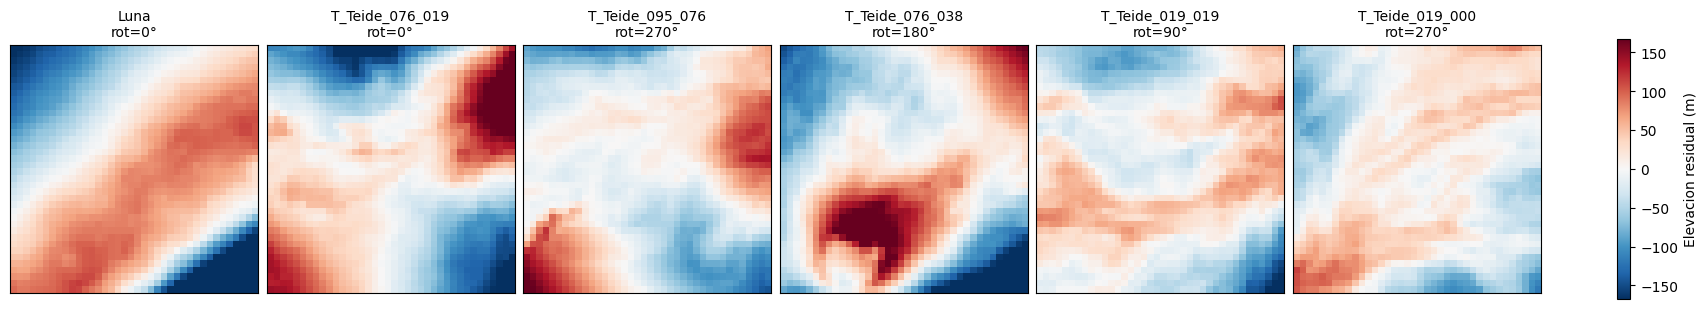

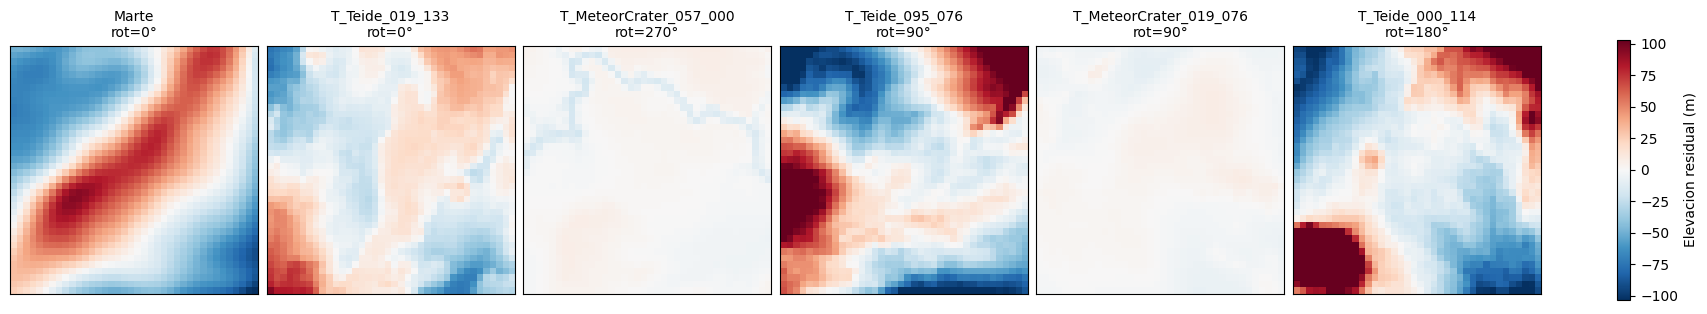

In [ ]:
def visualizar(nombre):
    indice=referencias[nombre]
    ref=tablas_planeta[nombre].loc[indice]
    lista=[(nombre,ref,0)]
    porid=tabla_tierra.set_index('parche_id')
    for _,f in rankings[nombre].head(5).iterrows():
        lista.append((f['parche_id'],porid.loc[f['parche_id']],int(f['rotacion_grados'])))
    imgs=[]
    for lab,f,ang in lista:
        zz=sin_plano(parche(f))
        imgs.append(np.rot90(zz,(ang//90)%4))
    vals=np.concatenate([z[np.isfinite(z)] for z in imgs])
    lim=max(float(np.nanpercentile(np.abs(vals),97)),1e-6)
    fig,axs=plt.subplots(1,len(imgs),figsize=(17,3.8),constrained_layout=True)
    for ax,z,(lab,_,ang) in zip(axs,imgs,lista):
        im=ax.imshow(z,cmap='RdBu_r',vmin=-lim,vmax=lim)
        ax.set_title(f'{lab}\nrot={ang}°',fontsize=10)
        ax.set_xticks([]);ax.set_yticks([])
    fig.colorbar(im,ax=axs,shrink=.7,label='Elevacion residual (m)')
    fig.savefig(SALIDAS/f'top5_{nombre.lower()}.png',dpi=150,bbox_inches='tight')
    plt.show()

for nombre in rankings: visualizar(nombre)

## PASO 33 — Elegir hasta ocho referencias no superpuestas por planeta y ejecutar búsquedas

Repite la búsqueda para distintas pendientes, no solo para una referencia lunar.

In [ ]:
pesos_prueba=[0,.25,.5,.75,1.]
registros=[]; sensibilidad=[]; detalle=[]
for nombre,t in tablas_planeta.items():
    orden=t['pendiente_media'].sort_values().index.to_list()
    elegidos=[referencias[nombre]]
    objetivos=np.linspace(0,len(orden)-1,min(16,len(orden)),dtype=int)
    for pos in objetivos:
        idx=orden[pos]
        f=t.loc[idx]
        if all(not(abs(f['fila']-t.loc[j,'fila'])<TAM_PIX and
                   abs(f['col']-t.loc[j,'col'])<TAM_PIX) for j in elegidos):
            elegidos.append(idx)
        if len(elegidos)>=8:break
    for idx in elegidos:
        base,df=buscar(nombre,idx)
        identificador=t.loc[idx,'parche_id']
        primero=base.iloc[0]
        registros.append({'cuerpo':nombre,'referencia':identificador,
            'mejor_tierra':primero['parche_id'],'region':primero['region'],
            'score_final':primero['score_final'],
            'distancia_fisica':primero['distancia_fisica'],
            'corr_forma':primero['corr_forma']})
        copia=base.copy();copia['cuerpo']=nombre;copia['referencia']=identificador
        detalle.append(copia)
        top_base=set(base.head(3)['parche_id'])
        for peso in pesos_prueba:
            otra=combinar(df,peso)
            top=set(otra.head(3)['parche_id'])
            sensibilidad.append({'cuerpo':nombre,'referencia':identificador,
                'peso_fisico':peso,'mismo_top1':int(otra.iloc[0]['parche_id']==primero['parche_id']),
                'jaccard_top3':len(top&top_base)/len(top|top_base)})

## PASO 34 — Resumir los rankings multilunares y multimarcianos

Compara el resultado más cercano por referencia; no interpretes los scores normalizados como porcentajes de exactitud.

In [ ]:
resumen=pd.DataFrame(registros)
tabla_sens=pd.DataFrame(sensibilidad)
tabla_detalle=pd.concat(detalle,ignore_index=True)
display(resumen.round(4))
estabilidad=tabla_sens.groupby(['cuerpo','peso_fisico'])[['mismo_top1','jaccard_top3']].mean()*100
print('Sensibilidad contra pesos 50/50 (no exactitud):')
display(estabilidad.round(1))

,cuerpo,referencia,mejor_tierra,region,score_final,distancia_fisica,corr_forma
0,Luna,L_038_095,T_Teide_076_019,Teide,0.0296,0.0594,0.6913
1,Luna,L_038_000,T_MeteorCrater_076_000,MeteorCrater,0.0888,0.0485,0.5817
2,Luna,L_000_057,T_Teide_095_038,Teide,0.0059,0.0428,0.7613
3,Luna,L_000_095,T_Teide_019_133,Teide,0.0089,0.0880,0.8795
4,Luna,L_038_038,T_Teide_095_038,Teide,0.0059,0.0317,0.8898
5,Luna,L_133_038,T_Teide_076_038,Teide,0.0858,0.0922,0.6685
6,Luna,L_095_057,T_Teide_076_038,Teide,0.0473,0.0859,0.8258
7,Luna,L_133_133,T_Teide_095_038,Teide,0.0089,0.1211,0.7999
8,Marte,M_114_019,T_Teide_019_133,Teide,0.0621,0.0195,0.5945
9,Marte,M_019_000,T_MeteorCrater_000_000,MeteorCrater,0.0769,0.0057,0.5201


Sensibilidad contra pesos 50/50 (no exactitud):


mismo_top1  jaccard_top3
cuerpo peso_fisico                          
Luna   0.00                0.0          26.2
       0.25               62.5          67.5
       0.50              100.0         100.0
       0.75               75.0          55.0
       1.00               37.5          18.8
Marte  0.00                0.0           5.0
       0.25               75.0          48.8
       0.50              100.0         100.0
       0.75               75.0          51.2
       1.00               25.0           7.5

## PASO 35 — Visualizar sensibilidad de rankings a pesos

La coincidencia 100% en 50/50 es trivial: es el mismo ranking comparado consigo mismo.

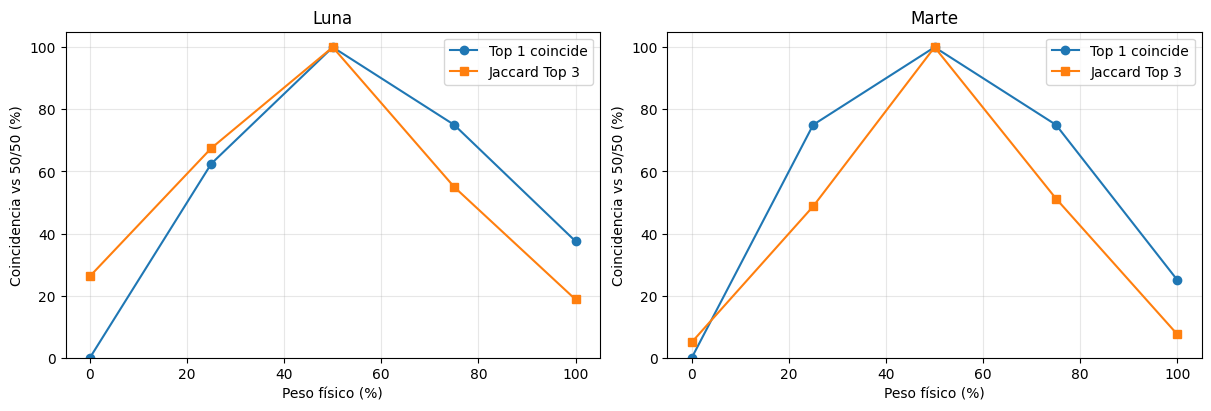

In [ ]:
fig,axs=plt.subplots(1,len(planetas),figsize=(6*len(planetas),4),squeeze=False,constrained_layout=True)
for ax,(nombre,d) in zip(axs[0],estabilidad.groupby(level=0)):
    tabla=d.droplevel(0)
    ax.plot(tabla.index*100,tabla['mismo_top1'],marker='o',label='Top 1 coincide')
    ax.plot(tabla.index*100,tabla['jaccard_top3'],marker='s',label='Jaccard Top 3')
    ax.set_title(nombre);ax.set_xlabel('Peso físico (%)');ax.set_ylabel('Coincidencia vs 50/50 (%)')
    ax.set_ylim(0,105);ax.legend();ax.grid(alpha=.3)
plt.show()

## PASO 36 — Mostrar varias correspondencias planetarias en paralelo

Ilustraciones para presentar los resultados del hackathon; mallas referidas a alturas residuales, no fotografías.

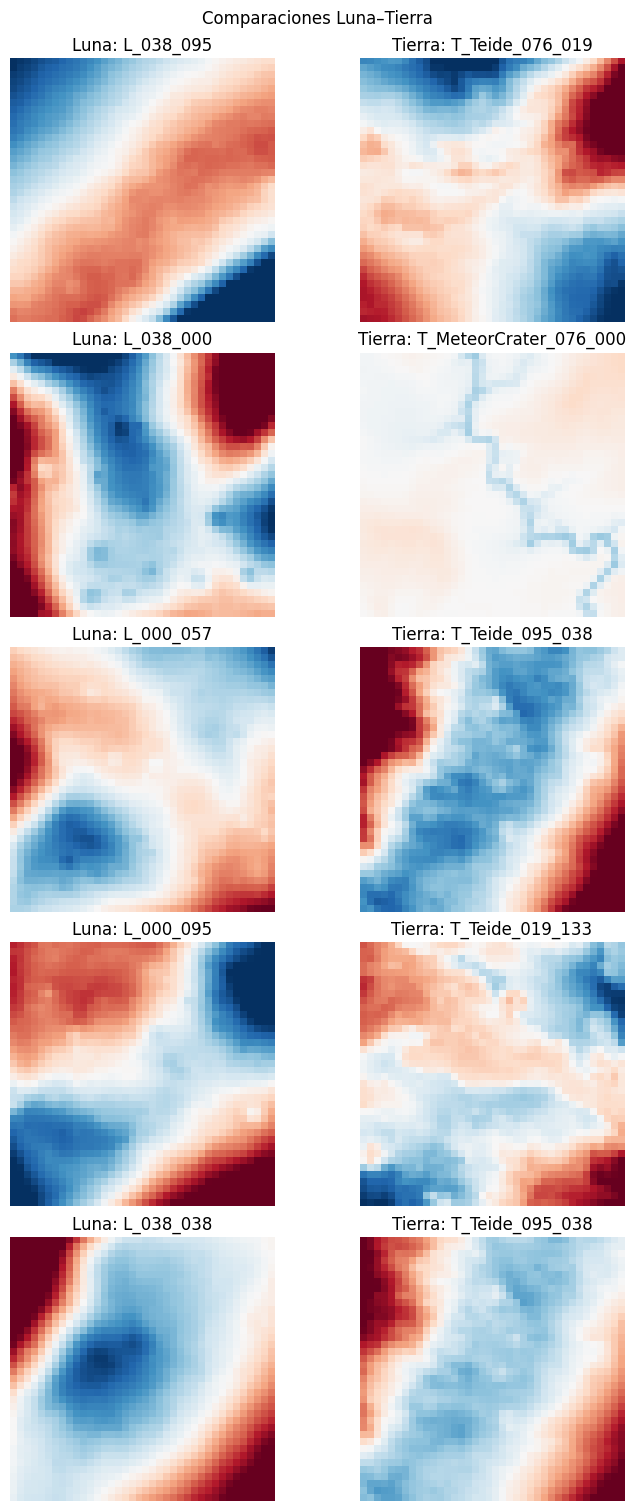

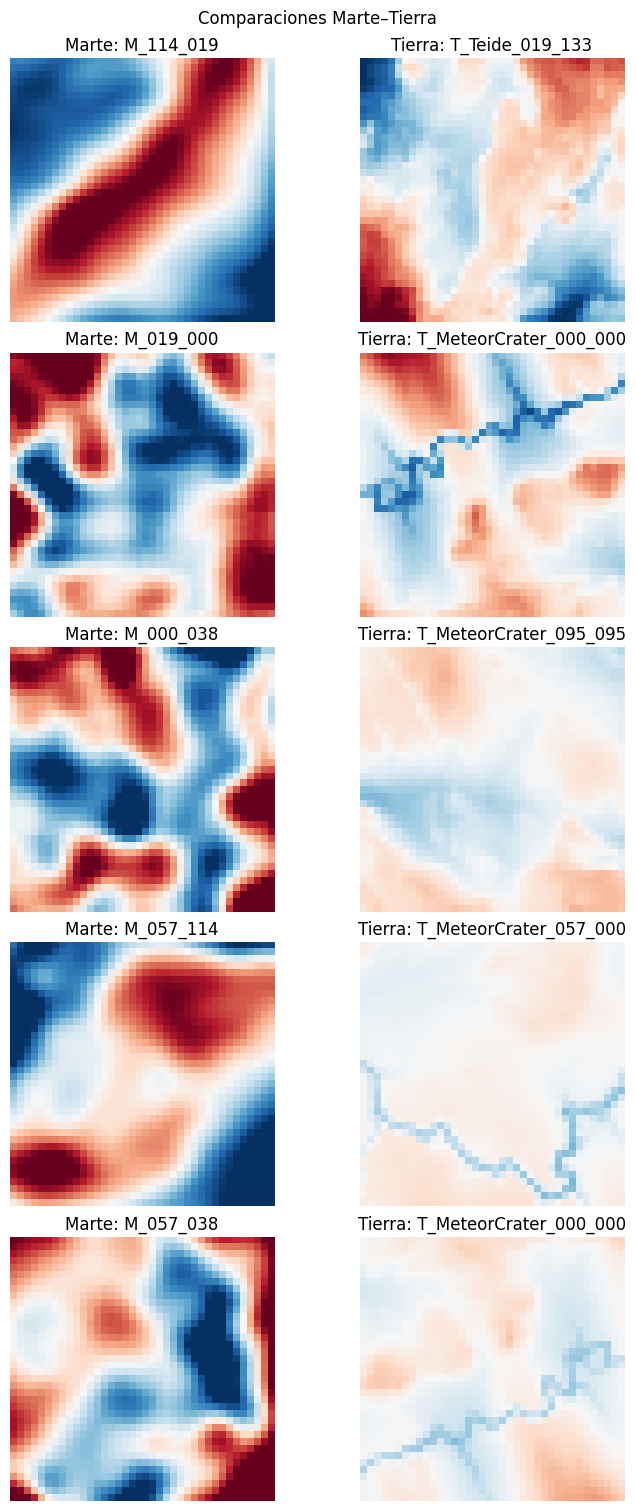

In [ ]:
for nombre,t in tablas_planeta.items():
    r=resumen[resumen['cuerpo']==nombre].head(5)
    if r.empty: continue
    fig,axs=plt.subplots(len(r),2,figsize=(7,3*len(r)),squeeze=False,constrained_layout=True)
    for k,(_,reg) in enumerate(r.iterrows()):
        fila_ref=t[t['parche_id']==reg['referencia']].iloc[0]
        tierra=tabla_tierra[tabla_tierra['parche_id']==reg['mejor_tierra']].iloc[0]
        rr=sin_plano(parche(fila_ref));tt=sin_plano(parche(tierra))
        ang=tabla_detalle[(tabla_detalle['cuerpo']==nombre)&(tabla_detalle['referencia']==reg['referencia'])&
                          (tabla_detalle['parche_id']==reg['mejor_tierra'])].iloc[0]['rotacion_grados']
        tt=np.rot90(tt,(int(ang)//90)%4)
        v=np.concatenate([rr[np.isfinite(rr)],tt[np.isfinite(tt)]])
        lim=max(1e-6,np.percentile(np.abs(v),95))
        axs[k,0].imshow(rr,cmap='RdBu_r',vmin=-lim,vmax=lim)
        axs[k,1].imshow(tt,cmap='RdBu_r',vmin=-lim,vmax=lim)
        axs[k,0].set_title(f'{nombre}: {reg["referencia"]}')
        axs[k,1].set_title(f'Tierra: {reg["mejor_tierra"]}')
        for ax in axs[k]:ax.axis('off')
    fig.suptitle(f'Comparaciones {nombre}–Tierra')
    fig.savefig(SALIDAS/f'comparaciones_{nombre.lower()}.png',dpi=150,bbox_inches='tight')
    plt.show()

## PASO 37 — Diagnóstico de estabilidad multiescala en Tierra

Retoma el diagnóstico que antes descubrió mala correlación baja–alta en parches pequeños.

In [ ]:
# Evaluación rápida: correlación de rankings en tres escalas para una referencia terrestre.
# No es un benchmark de ahorro computacional: las características se precalculan en todas las escalas.
ejemplo_nombre=next(iter(terrenos_tierra))
p= piramides[ejemplo_nombre]
puntos=[]
for factor,d in p.items():
    n=d.copy();n['nombre']=ejemplo_nombre;n['cuerpo']='Tierra';n['crs']=terrenos_tierra[ejemplo_nombre]['crs']
    n.update(caracteristicas_dem(n['H'],n['dx'],n['dy']))
    # A tamaños muy gruesos, solo hay pocos píxeles por parche: saltar sin errores.
    tpar=crear_parches(n,f'esc{factor}')
    puntos.append((factor,len(tpar)))
print('Parches válidos por factor:',puntos)
print('Si la escala gruesa tiene pocos píxeles por parche, no debe usarse para descartar candidatos agresivamente.')

Parches válidos por factor: [(4, 0), (2, 4), (1, 30)]
Si la escala gruesa tiene pocos píxeles por parche, no debe usarse para descartar candidatos agresivamente.


## PASO 38 — Medir tiempos computacionales y tamaño de resultados

Métricas de escala actual. Para demostrar velocidad en un catálogo amplio habrá que ejecutar y medir una búsqueda selectiva.

In [ ]:
import time
print('Cantidad de DEMs terrestres:',len(terrenos_tierra))
print('Parches terrestres:',len(tabla_tierra))
print('Memoria matrices de elevación (MiB):',round(sum(d['H'].nbytes for d in TERRENOS.values())/(1024**2),2))
print('Candidatos evaluados de forma en última búsqueda:',{nombre:len(d) for nombre,d in metricas.items()})
print('Nota: todavía no se calcula el costo de una búsqueda a escala planetaria completa.')

Cantidad de DEMs terrestres: 4
Parches terrestres: 170
Memoria matrices de elevación (MiB): 0.61
Candidatos evaluados de forma en última búsqueda: {'Luna': 170, 'Marte': 170}
Nota: todavía no se calcula el costo de una búsqueda a escala planetaria completa.


## PASO 39 — Exportar todos los CSV, mapas y un paquete ZIP

Incluye rankings individuales, pruebas de pesos y GeoTIFF recortados descargados; sin proclamar analogía geológica validada.

In [ ]:
import json, zipfile
tabla_tierra.to_csv(SALIDAS/'vectores_tierra.csv',index=False)
for nombre,t in tablas_planeta.items():
    t.to_csv(SALIDAS/f'vectores_{nombre.lower()}.csv',index=False)
for nombre,r in rankings.items():
    r.to_csv(SALIDAS/f'ranking_{nombre.lower()}_tierra.csv',index=False)
resumen.to_csv(SALIDAS/'resumen_multi_planetario.csv',index=False)
tabla_sens.to_csv(SALIDAS/'sensibilidad_pesos.csv',index=False)
tabla_detalle.to_csv(SALIDAS/'rankings_completos.csv',index=False)
config={'resolucion_m':RES_M,'parche_m':TAM_PIX*RES_M,
        'cuerpos_disponibles':list(planetas),'zonas_terrestres':list(terrenos_tierra),
        'normalizacion':'mediana e IQR terrestres','peso_fisico':PESO_FISICO,
        'candidatos_geom':CANDIDATOS_GEOM,'validacion':'exploratoria, no geologica'}
(SALIDAS/'configuracion.json').write_text(json.dumps(config,indent=2,ensure_ascii=False))
zipname=str(SALIDAS.parent/'Resultados_HackNASA_Tierra_Luna_Marte.zip')
with zipfile.ZipFile(zipname,'w',zipfile.ZIP_DEFLATED) as zf:
    for f in SALIDAS.iterdir():
        if f.is_file(): zf.write(f,arcname=f.name)
print('ZIP listo:',zipname)
from google.colab import files
files.download(zipname)

ZIP listo: /content/Resultados_HackNASA_Tierra_Luna_Marte.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Al terminar

Puedes descargar el ZIP de resultados generado en el paso 39. Este notebook usa fuentes públicas sin Google Drive, por lo que tus compañeros lo pueden ejecutar con una cuenta de Colab. **La conexión a la red, las cuotas del proveedor y la descarga completa (si DLR no acepta rangos) pueden afectar el tiempo/costo computacional.**

**Precauciones científicas:** Copernicus es DSM (incluye objetos de superficie). Los datums verticales de Tierra/Luna/Marte difieren. Los scores son exploratorios: los mapas y el ranking no garantizan analogía geológica ni seguridad para un rover. La selección de 15 km de relieve por variación de elevación es una heurística, no una muestra representativa.
